In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
data = pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/Student Performance clustering.csv")
data.head()

,StudentID,Age,StudyHours,Attendance,AssignmentScore,ExamScore,SleepHours
0,1,20,1.5,62,45,42,6.5
1,2,21,2.5,78,65,64,7.0
2,3,19,4.5,92,88,86,7.5
3,4,22,5.0,72,82,68,6.0
4,5,20,3.1,85,73,78,7.2


In [32]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   StudentID        200 non-null    int64  
 1   Age              200 non-null    int64  
 2   StudyHours       200 non-null    float64
 3   Attendance       200 non-null    int64  
 4   AssignmentScore  200 non-null    int64  
 5   ExamScore        200 non-null    int64  
 6   SleepHours       200 non-null    float64
dtypes: float64(2), int64(5)
memory usage: 11.1 KB


In [33]:
data.duplicated().sum()

np.int64(0)

In [34]:
def chkOutliers(data, column):
    plt.figure(figsize=(7,3))
    plt.subplot(1,2,1)  #row size, column size, plot no
    plt.boxplot(data[column])
    plt.subplot(1,2,2)
    m = data[column].mean()
    std = data[column].std()
    sns.histplot(data[column], kde=True)
    plt.axvline(m, color='green')
    plt.axvline(m - 3 * std, color='red')
    plt.axvline(m + 3 * std, color='red')
    plt.show()

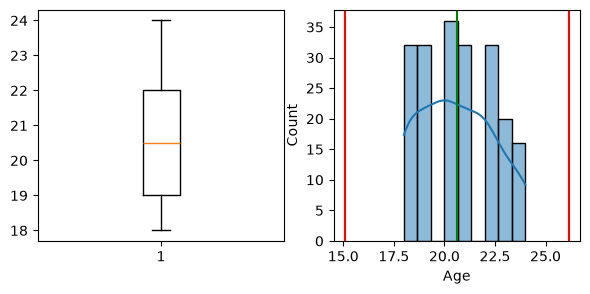

In [35]:
chkOutliers(data,'Age')

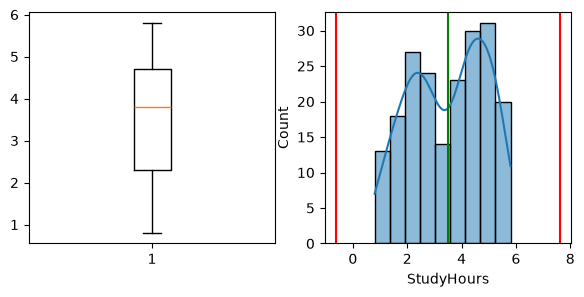

In [36]:
chkOutliers(data,'StudyHours')

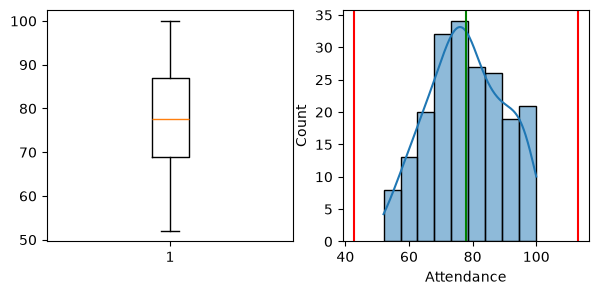

In [37]:
chkOutliers(data,'Attendance')

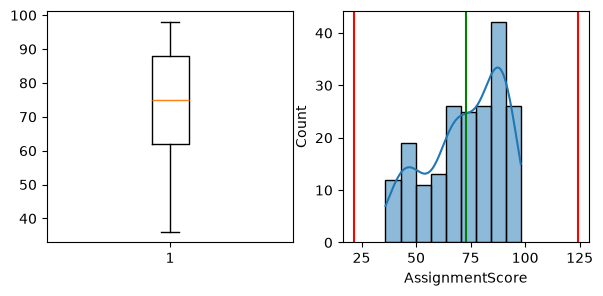

In [38]:
chkOutliers(data,'AssignmentScore')

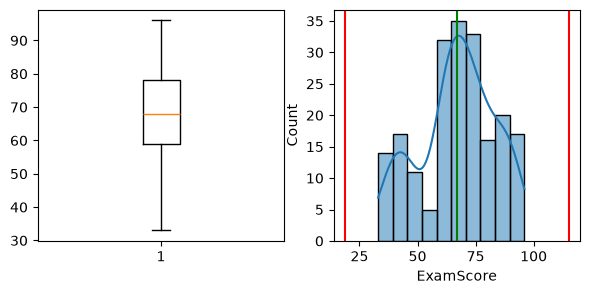

In [39]:
chkOutliers(data,'ExamScore')

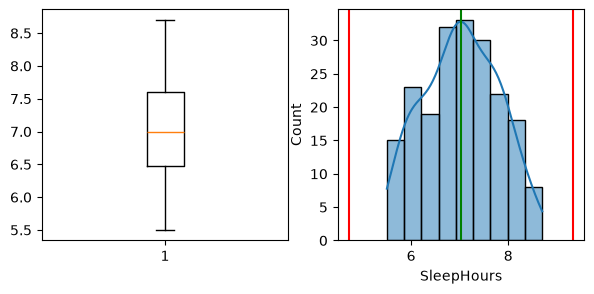

In [40]:
chkOutliers(data,'SleepHours')

<Axes: >

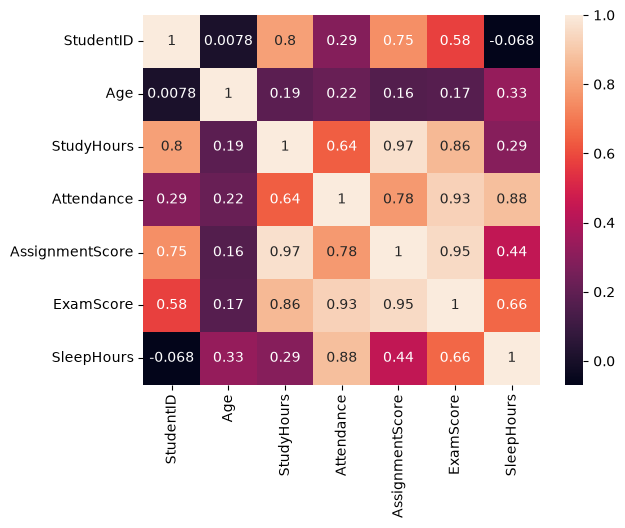

In [41]:
sns.heatmap(data.corr(), annot=True)

In [42]:
X = data.drop('StudentID', axis=1)

In [43]:
from sklearn.cluster import KMeans

In [44]:
from sklearn.metrics import silhouette_score

In [45]:
k = []
inertia = []
sil_coef = []

for i in range(3, 15):
    km = KMeans(n_clusters=i)
    km.fit(X)
    train_pred = km.predict(X)
    k.append(i)
    inertia.append(km.inertia_)
    sil_coef.append(silhouette_score(X, train_pred))
    

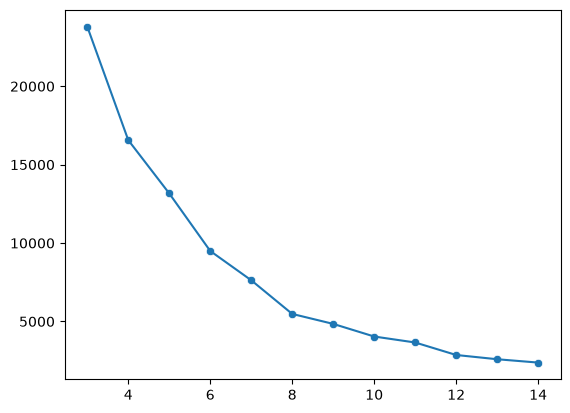

In [46]:
sns.lineplot(x=k, y=inertia)
sns.scatterplot(x=k, y=inertia)
plt.show()

In [47]:
import matplotlib.pyplot as plt

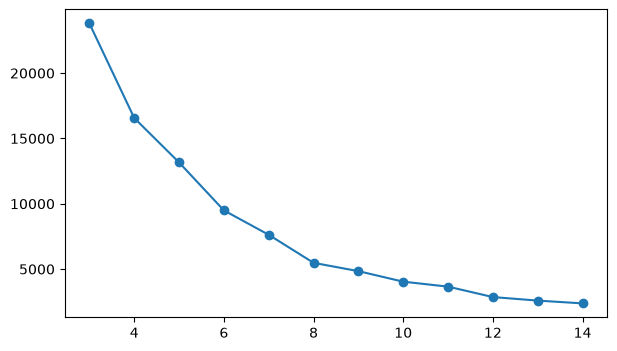

In [48]:
plt.figure(figsize=(7,4))
plt.plot(k, inertia, marker='o')

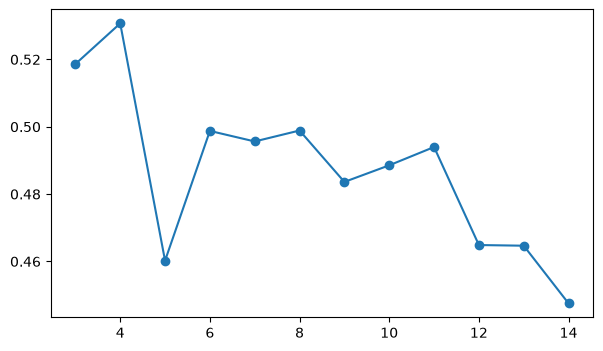

In [49]:
plt.figure(figsize=(7,4))
plt.plot(k, sil_coef, marker='o')

In [59]:
km = KMeans(n_clusters=6)
km.fit(X)
train_pred = km.predict(X)

In [60]:
centers = km.cluster_centers_
centers

array([[20.51020408,  2.66530612, 79.51020408, 66.87755102, 64.83673469,
         7.34081633,  2.91836735],
       [20.        ,  1.29166667, 58.83333333, 42.125     , 38.70833333,
         6.175     ,  5.625     ],
       [20.975     ,  4.7775    , 94.725     , 91.325     , 88.6       ,
         7.99      ,  0.9       ],
       [21.19047619,  4.68333333, 80.85714286, 86.        , 75.61904762,
         6.92142857,  3.52380952],
       [21.36842105,  2.05263158, 68.78947368, 51.26315789, 46.94736842,
         6.99473684,  2.42105263],
       [19.38461538,  4.27307692, 68.42307692, 78.73076923, 64.38461538,
         5.92307692,  4.19230769]])

In [61]:
km.inertia_

9954.120581722163

In [62]:
silhouette_score(X, train_pred)

0.4799354286869422

In [63]:
X['Label'] = km.labels_

In [64]:
X.head()

,Age,StudyHours,Attendance,AssignmentScore,ExamScore,SleepHours,Label
0,20,1.5,62,45,42,6.5,1
1,21,2.5,78,65,64,7.0,0
2,19,4.5,92,88,86,7.5,2
3,22,5.0,72,82,68,6.0,5
4,20,3.1,85,73,78,7.2,3


In [65]:
X.columns

Index(['Age', 'StudyHours', 'Attendance', 'AssignmentScore', 'ExamScore',
       'SleepHours', 'Label'],
      dtype='str')

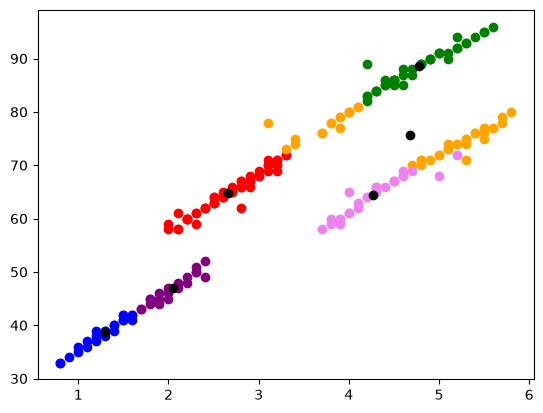

In [66]:
plt.scatter(X[X['Label']==0]['StudyHours'],
            X[X['Label']==0]['ExamScore'], color='red')
plt.scatter(X[X['Label']==1]['StudyHours'],
            X[X['Label']==1]['ExamScore'], color='blue')
plt.scatter(X[X['Label']==2]['StudyHours'],
            X[X['Label']==2]['ExamScore'], color='green')
plt.scatter(X[X['Label']==3]['StudyHours'],
            X[X['Label']==3]['ExamScore'], color='orange')
plt.scatter(X[X['Label']==4]['StudyHours'],
            X[X['Label']==4]['ExamScore'], color='purple')
plt.scatter(X[X['Label']==5]['StudyHours'],
            X[X['Label']==5]['ExamScore'], color='violet')
# plt.scatter(X[X['Label']==6]['StudyHours'],
#             X[X['Label']==6]['ExamScore'], color='yellow')
# plt.scatter(X[X['Label']==7]['StudyHours'],
#             X[X['Label']==7]['ExamScore'], color='pink')
plt.scatter(centers[:, 1], centers[:,4], color='black')